# 31 — Successful warnings, missed events and false alarms

Existing Notebook27 primary MA3 policy only. No budget analysis, no model refit, no later-year outcomes. Examples are illustrative retrospective selections, not representative performance estimates.

The last cell reads saved results without rerunning.

In [1]:
from pathlib import Path
ROOT=Path.cwd()
if (ROOT/"Weikun").is_dir():ROOT=ROOT/"Weikun"
OUTPUT=ROOT/"warning_case_outputs"/"case_review_20261101"
print(OUTPUT.resolve())

C:\Users\41240\OneDrive\文档\GitHub\practicum-project\Weikun\warning_case_outputs\case_review_20261101


In [2]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
MODELS=['Dynamic Panel FE','XGBoost','Random Forest']
COLORS=['#64748B','#2563EB','#087F78']
def tag(m):return m.lower().replace(' ','_')
def run(root,output):
 root,output=Path(root),Path(output);output.mkdir(parents=True,exist_ok=True);fig=output/'figures';fig.mkdir(exist_ok=True)
 source=root/'outbreak_task_outputs/case_surge_v1_20261101'
 daily=pd.read_csv(source/'daily_event_labels_2020.csv.gz',dtype={'zip':'string'},parse_dates=['date']).set_index(['zip','date']).sort_index()
 warnings={m:pd.read_csv(source/(tag(m)+'_assessment_warning_episodes.csv'),dtype={'zip':'string'},parse_dates=['forecast_origin','matched_event_date']) for m in MODELS}
 events={m:pd.read_csv(source/(tag(m)+'_assessment_event_detection.csv'),dtype={'zip':'string'},parse_dates=['event_date']) for m in MODELS}
 risks={m:pd.read_csv(source/(tag(m)+'_risk_scores.csv.gz'),dtype={'zip':'string'},parse_dates=['forecast_origin']).set_index(['zip','forecast_origin']).sort_index() for m in MODELS}
 thresholds=pd.read_csv(source/'warning_metrics.csv').query("phase=='assessment'").set_index('model').threshold.to_dict()
 paths=[root/'rolling_trajectory_outputs/rolling60_weekly_development_20261027/predictions.npz',root/'xgboost_trajectory_outputs/xgb60_weekly_development_20261027/predictions.npz',root/'random_forest_trajectory_outputs/rf60_weekly_development_20261027/predictions.npz']
 arrays={m:np.load(p,allow_pickle=False) for m,p in zip(MODELS,paths)}
 ref=arrays[MODELS[0]]
 for a in arrays.values():
  for k in ['zip','forecast_origins','actual_cases','horizons']:assert np.array_equal(a[k],ref[k])
 # Explain ALL missed events using the saved eligibility, risk and issue policy.
 reasons=[]
 for m in MODELS:
  for e in events[m].loc[~events[m].detected].itertuples():
   possible=pd.date_range(e.event_date-pd.Timedelta(days=3),e.event_date-pd.Timedelta(days=1))
   checks=[]
   for d in possible:
    if (e.zip,d) not in risks[m].index:continue
    r=risks[m].loc[(e.zip,d)]
    if bool(r.eligible) and float(r.risk_score)>thresholds[m]:checks.append(d)
   if not checks:reason='No eligible score exceeded threshold'
   else:
    blocked=[]
    for d in checks:
     recent=warnings[m].loc[warnings[m].zip.eq(e.zip)&warnings[m].forecast_origin.le(d)&warnings[m].forecast_origin.gt(d-pd.Timedelta(days=7))]
     blocked.append(len(recent)>0)
    reason='Above-threshold opportunity blocked by cooldown' if all(blocked) else 'Needs matching review'
   reasons.append(dict(model=m,zip=e.zip,event_date=e.event_date,reason=reason,above_threshold_origins=len(checks)))
 missed=pd.DataFrame(reasons);missed.to_csv(output/'missed_event_reasons.csv',index=False)
 assert not missed.reason.eq('Needs matching review').any()
 summary=missed.groupby(['model','reason']).size().unstack(fill_value=0).reindex(MODELS).reset_index()
 summary.to_csv(output/'missed_reason_summary.csv',index=False)
 # Deterministic illustrative examples: outcome strata, median actual MA3, no performance tuning.
 merged=events[MODELS[0]][['zip','event_date','detected']].rename(columns={'detected':MODELS[0]})
 for m in MODELS[1:]:merged=merged.merge(events[m][['zip','event_date','detected']].rename(columns={'detected':m}),on=['zip','event_date'],validate='one_to_one')
 pools={'shared_success':merged.loc[merged[MODELS].all(axis=1)].copy(),
        'xgb_miss_other_detect':merged.loc[~merged.XGBoost & (merged[MODELS[0]]|merged[MODELS[2]])].copy()}
 selected=[]
 for kind,pool in pools.items():
  pool['selection_ma3']=[daily.loc[(z,d),'ma'] for z,d in zip(pool.zip,pool.event_date)]
  pool=pool.sort_values(['selection_ma3','zip','event_date']);row=pool.iloc[len(pool)//2]
  matches=[]
  for m in MODELS:
   w=warnings[m];matches.extend(w.loc[w.zip.eq(row.zip)&w.matched_event_date.eq(row.event_date),'forecast_origin'].tolist())
  origin=min(matches)
  selected.append(dict(case=kind,zip=row.zip,forecast_origin=origin,event_date=row.event_date,pool_size=len(pool)))
 pool=warnings['XGBoost'].loc[~warnings['XGBoost'].true_warning].copy()
 pool['selection_ma3']=[daily.loc[(z,d),'ma'] for z,d in zip(pool.zip,pool.forecast_origin)]
 pool=pool.sort_values(['selection_ma3','zip','forecast_origin']);row=pool.iloc[len(pool)//2]
 selected.append(dict(case='xgb_false_warning',zip=row.zip,forecast_origin=row.forecast_origin,event_date=pd.NaT,pool_size=len(pool)))
 labels={'shared_success':'All three models detected this event','xgb_miss_other_detect':'XGBoost missed an event another model detected','xgb_false_warning':'XGBoost warning had no confirmation within 3 days'}
 plt.rcParams.update({'font.family':'Arial','font.size':12,'axes.spines.top':False,'axes.spines.right':False})
 detail=[];pathsout=[]
 for num,case in enumerate(selected,1):
  zipcode=case['zip'];origin=case['forecast_origin'];event=case['event_date'];one=daily.loc[zipcode]
  window=one.loc[origin-pd.Timedelta(days=14):origin+pd.Timedelta(days=9)]
  f,axes=plt.subplots(2,1,figsize=(11,7),gridspec_kw={'height_ratios':[1.2,1]})
  ax=axes[0];ax.plot(window.index,window.cases_today,color='#CBD5E1',label='Recorded daily cases')
  ax.plot(window.index,window.ma,color='#173654',lw=2,label='Actual trailing 3-day mean')
  ax.plot(window.index,window.threshold,'--',color='#D94841',label='Realized historical mean + 2 SD')
  qualifies=window[window.qualify];ax.scatter(qualifies.index,qualifies.ma,s=20,color='#D94841',label='Actual qualifying day',zorder=4)
  confirmed=window[window.onset];ax.scatter(confirmed.index,confirmed.ma,s=100,marker='*',color='#7C3AED',label='Event confirmation',zorder=5)
  ax.axvline(origin,color='black',ls=':',label='Selected forecast origin');ax.axvspan(origin,origin+pd.Timedelta(days=3),color='#DBEAFE',alpha=.5)
  ax.set(ylabel='Cases / mean cases');ax.xaxis.set_major_locator(mdates.DayLocator(interval=4));ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'));ax.legend(ncol=2,fontsize=9,loc='upper left');ax.grid(alpha=.15)
  z=np.flatnonzero(ref['zip']==zipcode)[0];j=np.flatnonzero(ref['forecast_origins'].astype('datetime64[D]')==origin.to_datetime64().astype('datetime64[D]'))[0]
  actual=ref['actual_cases'][z,j];targetdates=pd.date_range(origin+pd.Timedelta(days=1),periods=3)
  assert np.array_equal(actual,one.loc[targetdates,'cases_today'].to_numpy())
  axes[1].plot([1,2,3],actual,'o-',color='#173654',lw=2.8,label='Actual')
  for m,color in zip(MODELS,COLORS):
   pred=np.maximum(arrays[m]['raw_predictions'][z,j],0);axes[1].plot([1,2,3],pred,'o--',color=color,label=m)
   r=risks[m].loc[(zipcode,origin)];ww=warnings[m].loc[warnings[m].zip.eq(zipcode)&warnings[m].forecast_origin.eq(origin)]
   recent=warnings[m].loc[warnings[m].zip.eq(zipcode)&warnings[m].forecast_origin.lt(origin)&warnings[m].forecast_origin.gt(origin-pd.Timedelta(days=7))]
   eventrow=events[m].loc[events[m].zip.eq(zipcode)&events[m].event_date.eq(event)] if pd.notna(event) else pd.DataFrame()
   detail.append(dict(case=case['case'],model=m,zip=zipcode,forecast_origin=origin,event_date=event,eligible=bool(r.eligible),risk_score=r.risk_score,warning_threshold=thresholds[m],issued_warning_here=len(ww)>0,warning_correct_here=bool(ww.true_warning.any()),prior_warning_in_last_6_days=len(recent)>0,event_detected_in_any_1_3day_origin=bool(eventrow.detected.iloc[0]) if len(eventrow) else np.nan))
   for h in range(3):pathsout.append(dict(case=case['case'],model=m,zip=zipcode,forecast_origin=origin,horizon=h+1,target_date=targetdates[h],actual=actual[h],prediction=pred[h]))
  axes[1].set(xticks=[1,2,3],xlabel='Days ahead from the SAME forecast origin',ylabel='Daily cases');axes[1].legend(ncol=2,fontsize=10);axes[1].grid(alpha=.15)
  f.suptitle(f"{labels[case['case']]}\nZIP {zipcode}, forecast origin {origin:%Y-%m-%d}",fontsize=15)
  f.text(.5,.015,'Illustrative retrospective case. Future actuals and realized thresholds appear only for review.',ha='center',fontsize=10,color='#53677D')
  f.tight_layout(rect=[0,.04,1,.92]);f.savefig(fig/f'{num:02}_{case["case"]}.png',dpi=200,bbox_inches='tight');plt.close(f)
 pd.DataFrame(selected).to_csv(output/'selected_cases.csv',index=False);d=pd.DataFrame(detail);d.to_csv(output/'case_model_diagnostics.csv',index=False);pd.DataFrame(pathsout).to_csv(output/'case_three_day_paths.csv',index=False)
 counts=summary.set_index('model');f,ax=plt.subplots(figsize=(10,4.7));bottom=np.zeros(3)
 for col,color in zip(counts.columns,['#2563EB','#A0AFC0']):
  vals=counts[col].to_numpy();ax.bar(MODELS,vals,bottom=bottom,label=col,color=color);bottom+=vals
 ax.set(ylabel='Missed events',title='Why did the existing warning policy miss events?');ax.legend(fontsize=10);ax.grid(axis='y',alpha=.15);f.tight_layout();f.savefig(fig/'04_missed_event_reasons.png',dpi=200,bbox_inches='tight');plt.close(f)
 date_rows=[]
 for case in selected:
  for m in MODELS:
   w=warnings[m]
   if pd.notna(case['event_date']):q=w.loc[w.zip.eq(case['zip'])&w.matched_event_date.eq(case['event_date'])]
   else:q=w.loc[w.zip.eq(case['zip'])&w.forecast_origin.eq(case['forecast_origin'])]
   date_rows.append(dict(case=case['case'],model=m,zip=case['zip'],event_date=case['event_date'],matched_warning_origin=q.forecast_origin.iloc[0] if len(q) else pd.NaT,lead_days=q.lead_days.iloc[0] if len(q) else np.nan))
 pd.DataFrame(date_rows).to_csv(output/'case_event_warning_dates.csv',index=False)
 protocol=dict(source='Notebook27 primary MA3 warnings, unchanged',selection='Median actual MA3 within three retrospective outcome strata; stable ZIP/date tie-break; not representative sampling or threshold tuning',cases=labels,warning='Existing calibrated threshold, original7day cooldown,1..3day matching',diagnostic='Missed-event reason checks all three origins before confirmation; absence of eligible above-threshold opportunity vs cooldown block',plot='top realized MA3 and thresholds for review, bottom daily case paths issued from exactly one origin, all3models same origin',limits=['case examples cannot establish causal reasons','an event miss refers to the whole1..3day warning window, not just plotted origin','false warning means no qualifying confirmation in next3days, not absence of any later increase','confirmation is second abnormal day, not biological outbreak onset','no retraining, no budget tuning, no2021-2023data'],source_hashes={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in [source/'warning_metrics.csv',source/'task_definition.json']})
 (output/'case_review_definition.json').write_text(json.dumps(protocol,indent=2),encoding='utf-8')
 report='# Notebook31：预警案例与漏报诊断\n\n## 先看什么\n1. selected_cases.csv：三个例子的ZIP与日期。\n2. figures/01_shared_success.png：三个模型都成功检出的事件。\n3. figures/02_xgb_miss_other_detect.png：XGBoost漏报、其他模型检出的事件。\n4. figures/03_xgb_false_warning.png：XGBoost发出预警，但未来3天无事件确认。\n5. missed_reason_summary.csv：全部漏报的规则层面原因。\n\n## 图怎么读\n上图给出真实病例、真实3天均值及事后可计算的实际阈值，星号为事件确认日，黑虚线为选定预测日。未来真实值仅用于事后核对。红点仅表示当日满足条件，事件还需要连续两天和重置规则。下图比较从同一个日期出发的未来1/2/3天真实病例路径和预测路径。\n\n## 案例选择\n按结果分组后，取真实MA3中位数附近案例，避免只选最好看的图。这仍是解释性例子，不代表总体表现。成功/漏报评价用整个事件前1—3天窗口，而图中只展示一个共同预测日。\n\n'+pd.DataFrame(selected).to_string(index=False)+'\n\n## 所有漏报的诊断\n'+summary.to_string(index=False)+'\n\nNo eligible score exceeded threshold：事件前三天没有可预警、且风险分数超过现有阈值的机会。Above-threshold opportunity blocked by cooldown：虽然出现满足分数条件的机会，但过去7天已经发过预警，冷却规则阻止再次报警。这解释的是现有报警规则的行为，不是疫情机制或模型因果归因。\n\n误报也可能只是时间没有对上：未来3天没有确认，不能解释为之后永远没有病例上升。各例子的三个模型是否实际发报警、是否处于冷却期、风险分数是多少，请看case_model_diagnostics.csv。主事件定义与模型都不变，没有使用Notebook30的预算阈值。\n'
 (output/'START_HERE_CN.md').write_text(report,encoding='utf-8')
 (output/'verification.json').write_text(json.dumps(dict(common_forecasts_verified=True,actual_paths_match_daily_table=True,unresolved_missed_event_reasons=0,missed_events=len(missed),no_model_refit=True,notebook27_policy_unchanged=True),indent=2),encoding='utf-8')
 print(pd.DataFrame(selected).to_string(index=False));print(summary.to_string(index=False));return d


In [3]:
diagnostics=run(ROOT,OUTPUT)
display(diagnostics)

                 case   zip forecast_origin event_date  pool_size
       shared_success 07755      2020-11-14 2020-11-16        748
xgb_miss_other_detect 07869      2020-09-25 2020-09-26        153
    xgb_false_warning 08829      2020-11-27        NaT        161
           model  Above-threshold opportunity blocked by cooldown  No eligible score exceeded threshold
Dynamic Panel FE                                               84                                   158
         XGBoost                                               27                                   279
   Random Forest                                               49                                   185


,case,model,zip,forecast_origin,event_date,eligible,risk_score,warning_threshold,issued_warning_here,warning_correct_here,prior_warning_in_last_6_days,event_detected_in_any_1_3day_origin
0,shared_success,Dynamic Panel FE,07755,2020-11-14,2020-11-16,True,0.230317,0,True,True,False,True
1,shared_success,XGBoost,07755,2020-11-14,2020-11-16,True,-0.347832,0,False,False,False,True
2,shared_success,Random Forest,07755,2020-11-14,2020-11-16,True,-0.296889,0,False,False,False,True
3,xgb_miss_other_detect,Dynamic Panel FE,07869,2020-09-25,2020-09-26,True,0.053083,0,True,True,False,True
4,xgb_miss_other_detect,XGBoost,07869,2020-09-25,2020-09-26,True,-0.163132,0,False,False,False,False
5,xgb_miss_other_detect,Random Forest,07869,2020-09-25,2020-09-26,True,-0.093091,0,False,False,False,False
6,xgb_false_warning,Dynamic Panel FE,08829,2020-11-27,NaT,True,0.278634,0,True,False,False,NaN
7,xgb_false_warning,XGBoost,08829,2020-11-27,NaT,True,0.157649,0,True,False,False,NaN
8,xgb_false_warning,Random Forest,08829,2020-11-27,NaT,True,0.210258,0,True,False,False,NaN


# Notebook31：预警案例与漏报诊断

## 先看什么
1. selected_cases.csv：三个例子的ZIP与日期。
2. figures/01_shared_success.png：三个模型都成功检出的事件。
3. figures/02_xgb_miss_other_detect.png：XGBoost漏报、其他模型检出的事件。
4. figures/03_xgb_false_warning.png：XGBoost发出预警，但未来3天无事件确认。
5. missed_reason_summary.csv：全部漏报的规则层面原因。

## 图怎么读
上图给出真实病例、真实3天均值及事后可计算的实际阈值，星号为事件确认日，黑虚线为选定预测日。未来真实值仅用于事后核对。红点仅表示当日满足条件，事件还需要连续两天和重置规则。下图比较从同一个日期出发的未来1/2/3天真实病例路径和预测路径。

## 案例选择
按结果分组后，取真实MA3中位数附近案例，避免只选最好看的图。这仍是解释性例子，不代表总体表现。成功/漏报评价用整个事件前1—3天窗口，而图中只展示一个共同预测日。

                 case   zip forecast_origin event_date  pool_size
       shared_success 07755      2020-11-14 2020-11-16        748
xgb_miss_other_detect 07869      2020-09-25 2020-09-26        153
    xgb_false_warning 08829      2020-11-27        NaT        161

## 所有漏报的诊断
           model  Above-threshold opportunity blocked by cooldown  No eligible score exceeded threshold
Dynamic Panel FE                                               84                                   158
         XGBoost                                               27                                   279
   Random Forest                                               49                                   185

No eligible score exceeded threshold：事件前三天没有可预警、且风险分数超过现有阈值的机会。Above-threshold opportunity blocked by cooldown：虽然出现满足分数条件的机会，但过去7天已经发过预警，冷却规则阻止再次报警。这解释的是现有报警规则的行为，不是疫情机制或模型因果归因。

误报也可能只是时间没有对上：未来3天没有确认，不能解释为之后永远没有病例上升。各例子的三个模型是否实际发报警、是否处于冷却期、风险分数是多少，请看case_model_diagnostics.csv。主事件定义与模型都不变，没有使用Notebook30的预算阈值。


## 可以汇报的具体发现

- 成功案例07755：确认日11月16日。三种模型都提前检出，但不一定在同一天报警。图中统一展示11月14日的预测，不能理解为三种模型当日都报警，精确报警日期见case_event_warning_dates.csv。
- 漏报案例07869：9月26日确认。9月25日Dynamic Panel风险分数为0.053，高于0，发出预警；XGBoost为-0.163、Random Forest为-0.093，没有发出预警。这说明接近规则边界时，较小的预测差异也可能改变报警结果，不是对模型总体优劣的证明。
- 误报案例08829：11月27日三个模型都发出预警，但未来三天没有出现连续两个满足条件的日期，因此属于本任务下的误报。
- 全部漏报中，冷却规则对应的漏报数分别为Dynamic Panel84/242（34.7%）、XGBoost27/306（8.8%）、Random Forest49/234（20.9%）。其余漏报在事件前1—3天没有可报警且超过阈值的机会。不能把这些数量直接当成取消冷却后会新增的检出数，取消冷却会改变之后的整个报警序列。

分析意义：病例预测、事件定义和报警规则共同决定预警效果。下一步可在报告中展示三个例子说明总体指标背后的行为，不要求通过继续调参得到更好分数。


,case,zip,forecast_origin,event_date,pool_size
0,shared_success,07755,2020-11-14,2020-11-16,748
1,xgb_miss_other_detect,07869,2020-09-25,2020-09-26,153
2,xgb_false_warning,08829,2020-11-27,NaN,161


,case,model,zip,forecast_origin,event_date,eligible,risk_score,warning_threshold,issued_warning_here,warning_correct_here,prior_warning_in_last_6_days,event_detected_in_any_1_3day_origin
0,shared_success,Dynamic Panel FE,07755,2020-11-14,2020-11-16,True,0.230317,0,True,True,False,True
1,shared_success,XGBoost,07755,2020-11-14,2020-11-16,True,-0.347832,0,False,False,False,True
2,shared_success,Random Forest,07755,2020-11-14,2020-11-16,True,-0.296889,0,False,False,False,True
3,xgb_miss_other_detect,Dynamic Panel FE,07869,2020-09-25,2020-09-26,True,0.053083,0,True,True,False,True
4,xgb_miss_other_detect,XGBoost,07869,2020-09-25,2020-09-26,True,-0.163132,0,False,False,False,False
5,xgb_miss_other_detect,Random Forest,07869,2020-09-25,2020-09-26,True,-0.093091,0,False,False,False,False
6,xgb_false_warning,Dynamic Panel FE,08829,2020-11-27,NaN,True,0.278634,0,True,False,False,NaN
7,xgb_false_warning,XGBoost,08829,2020-11-27,NaN,True,0.157649,0,True,False,False,NaN
8,xgb_false_warning,Random Forest,08829,2020-11-27,NaN,True,0.210258,0,True,False,False,NaN


,model,Above-threshold opportunity blocked by cooldown,No eligible score exceeded threshold
0,Dynamic Panel FE,84,158
1,XGBoost,27,279
2,Random Forest,49,185


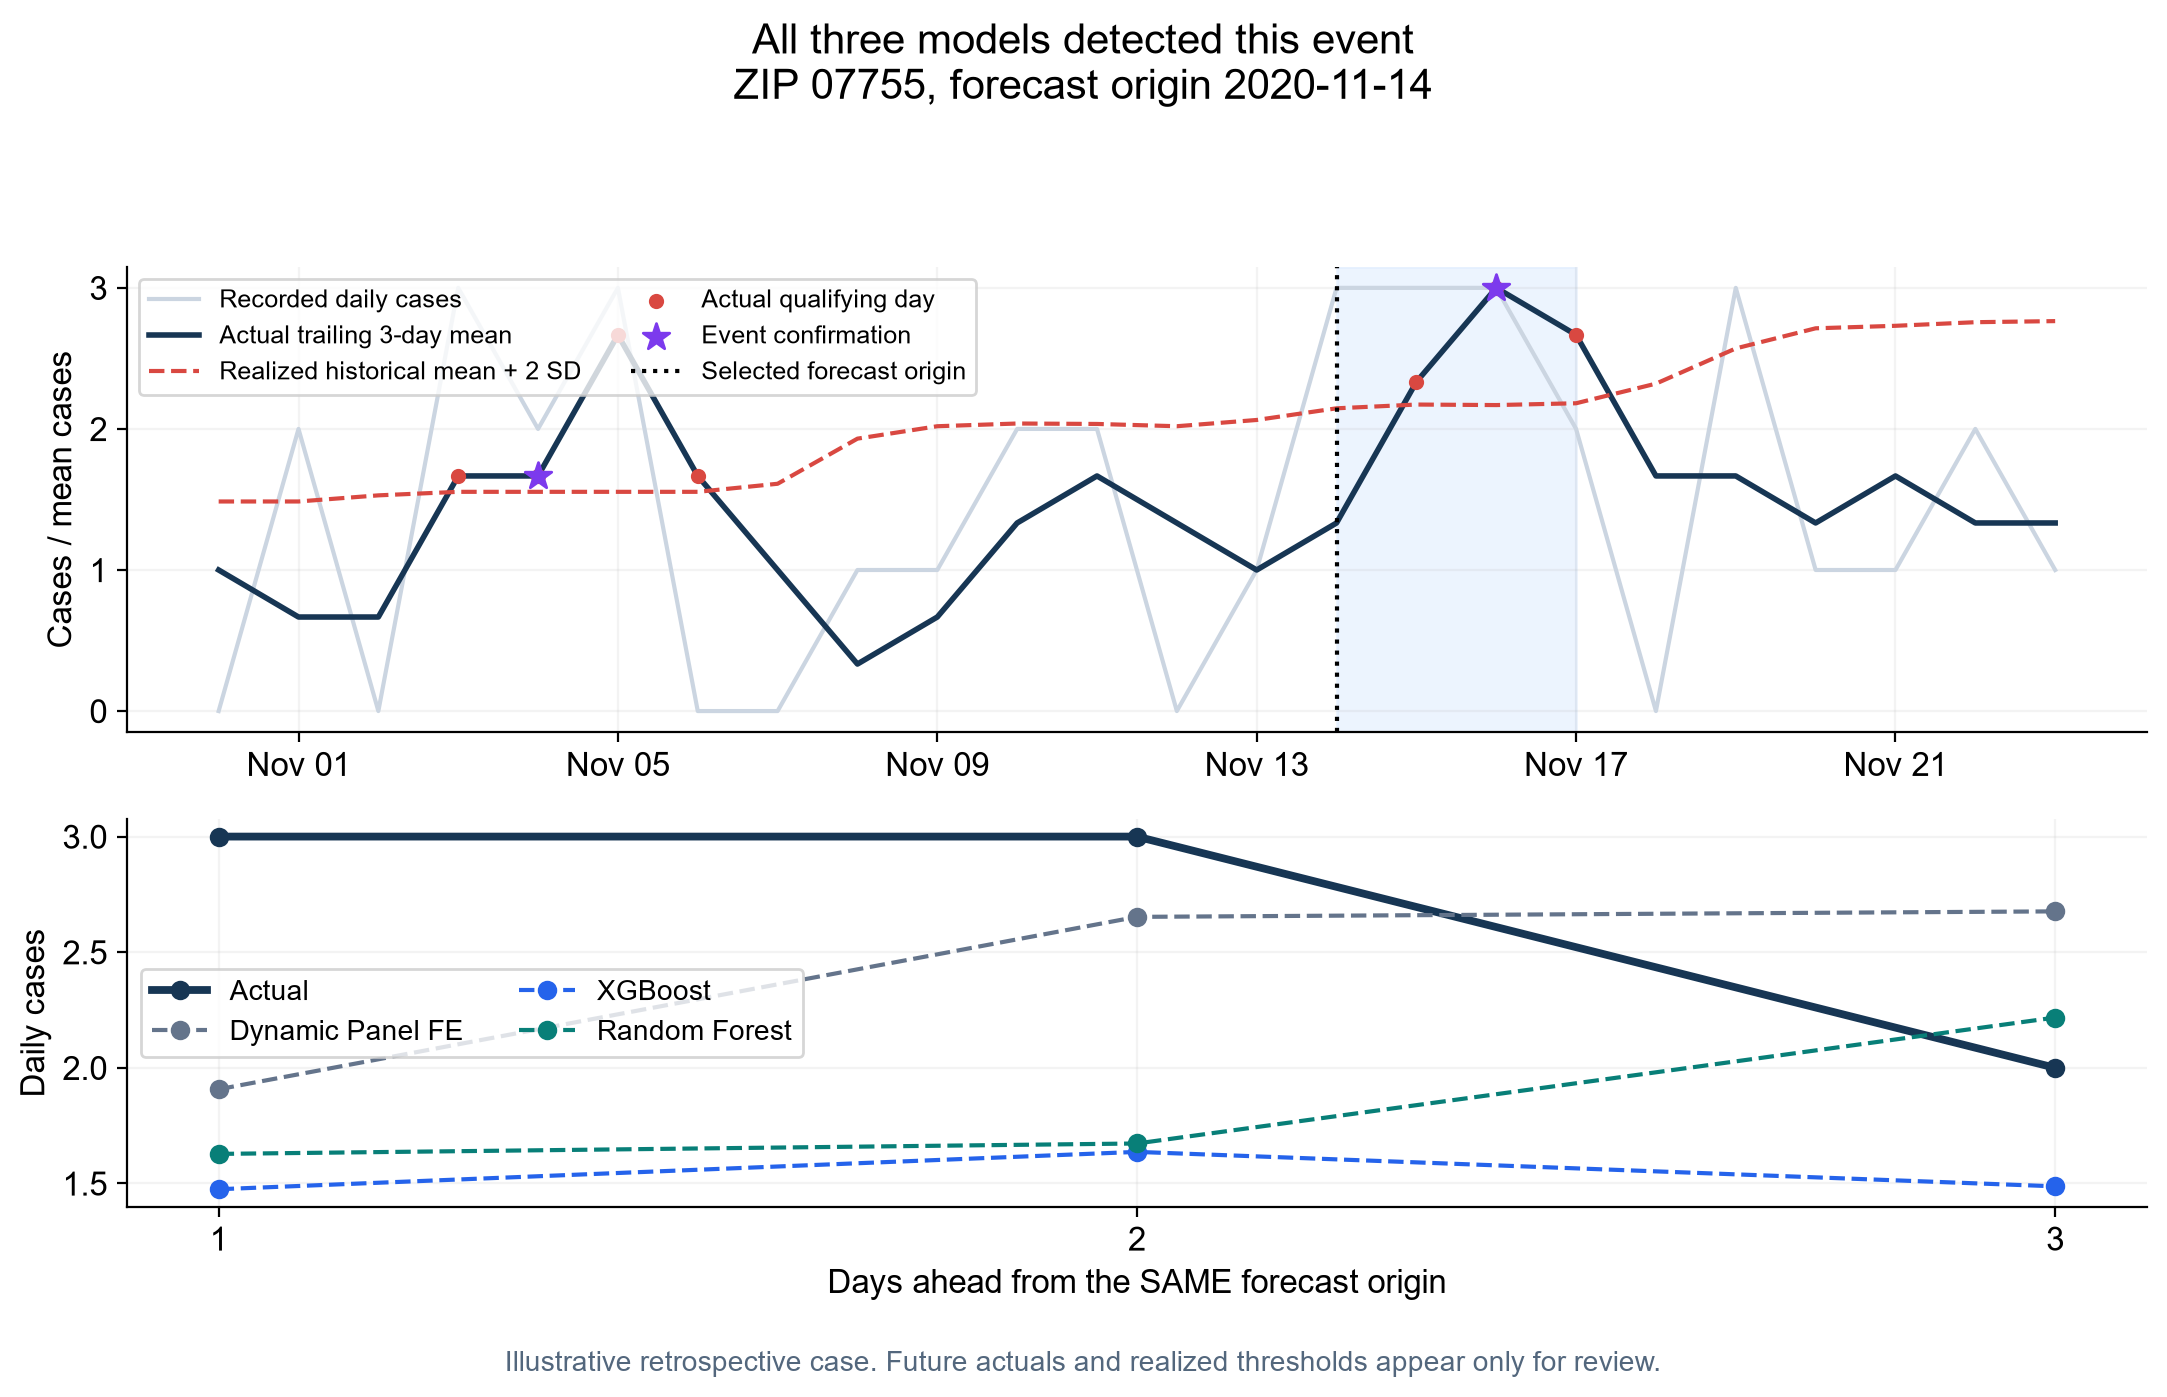

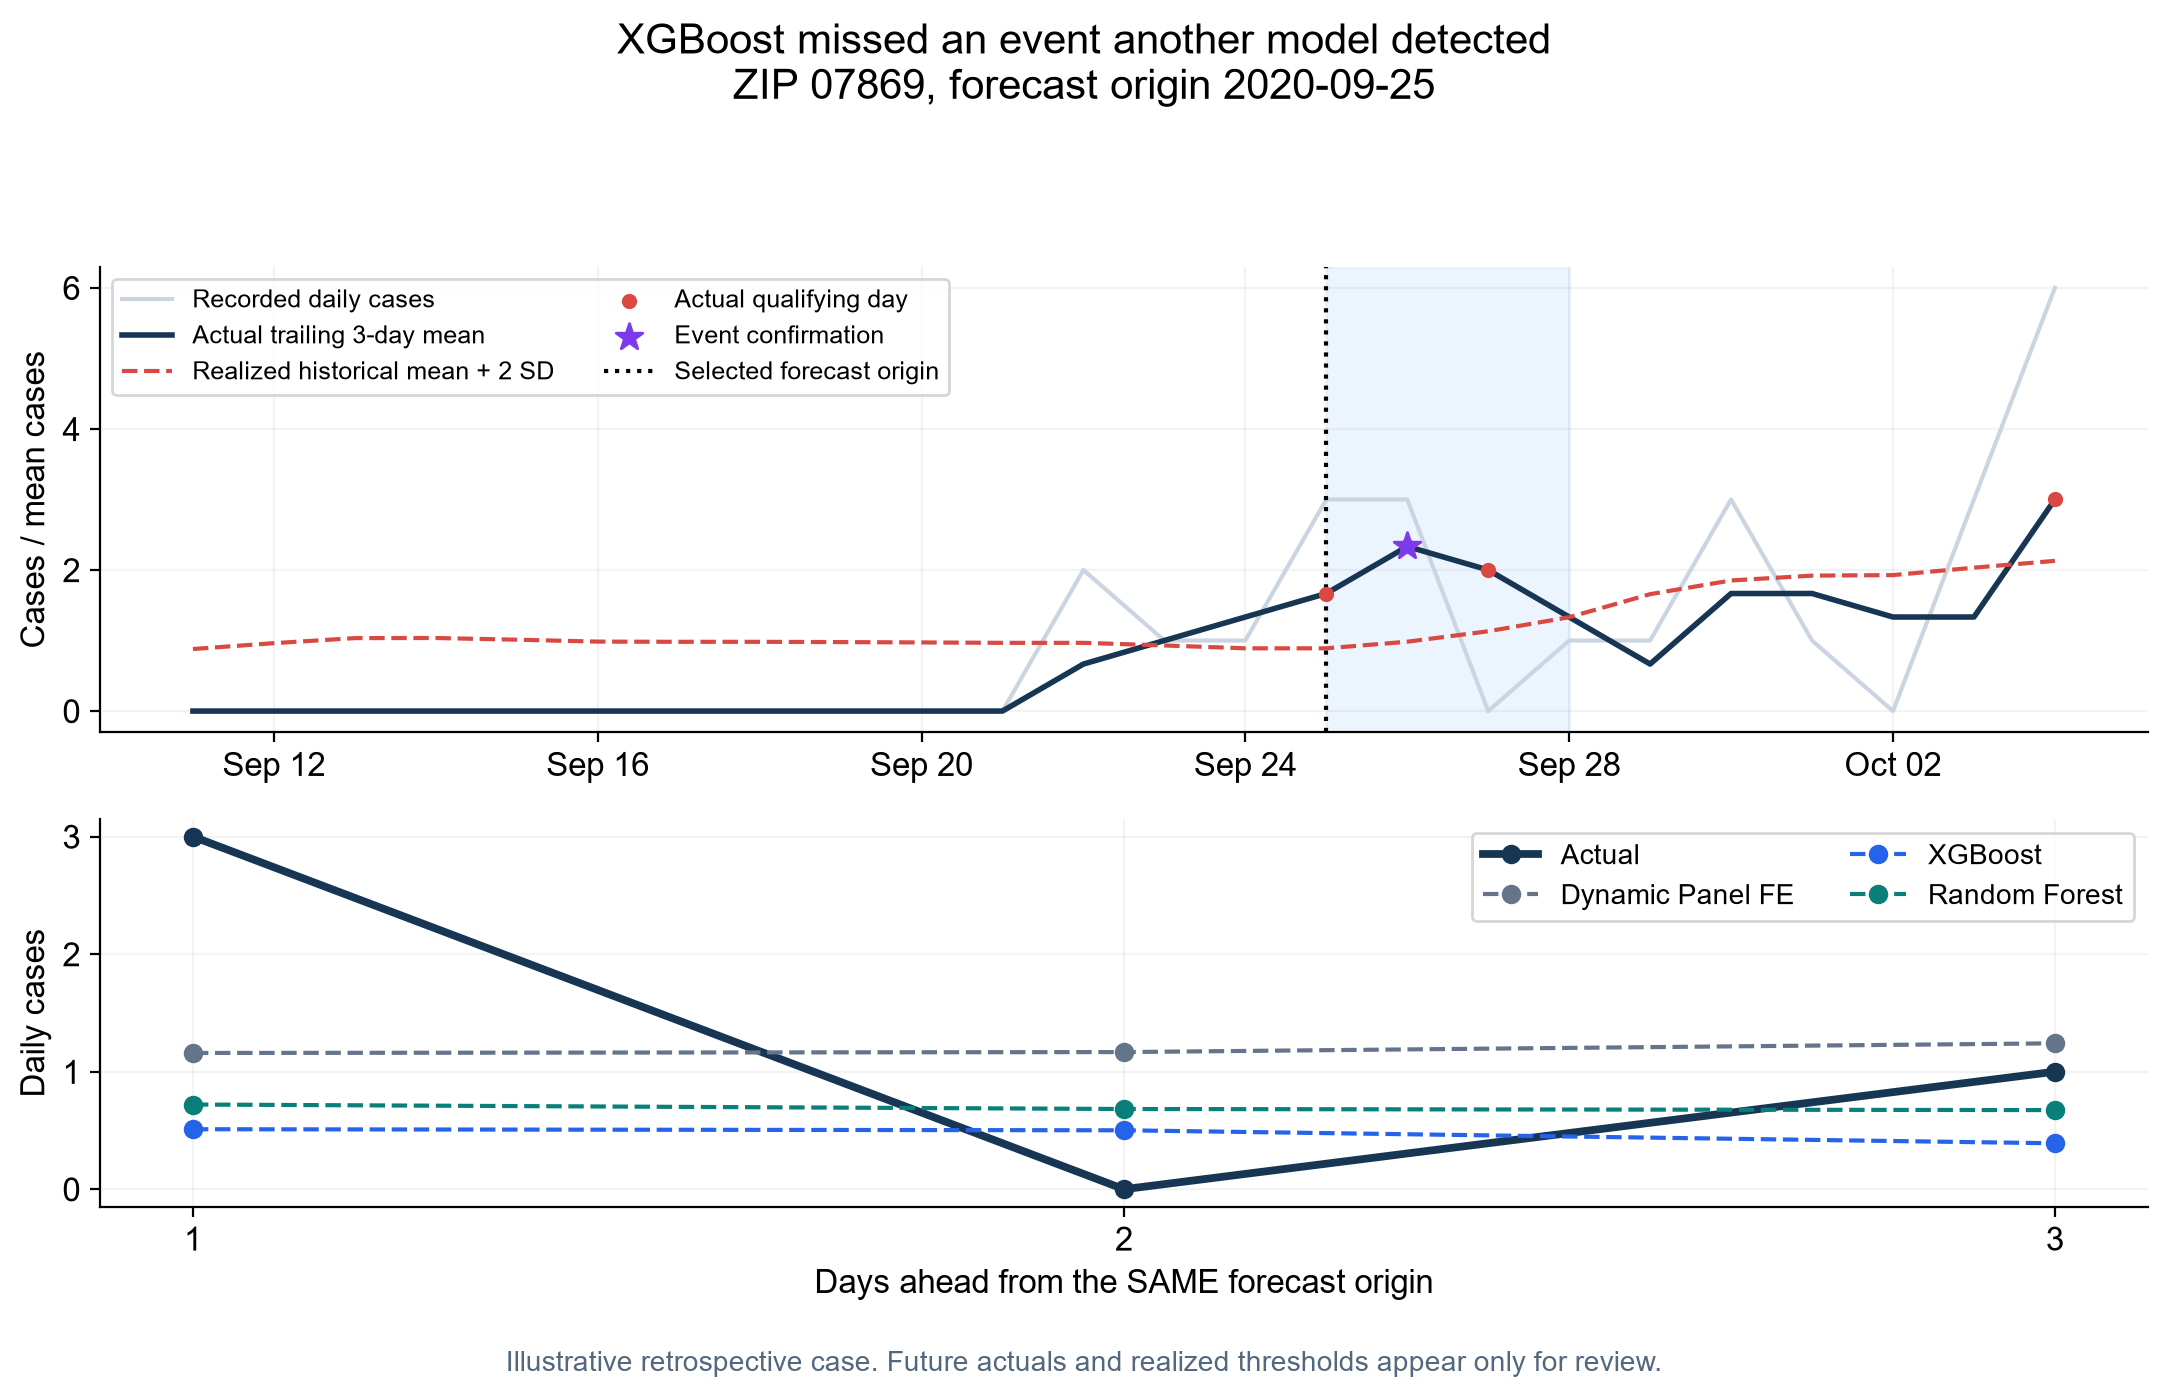

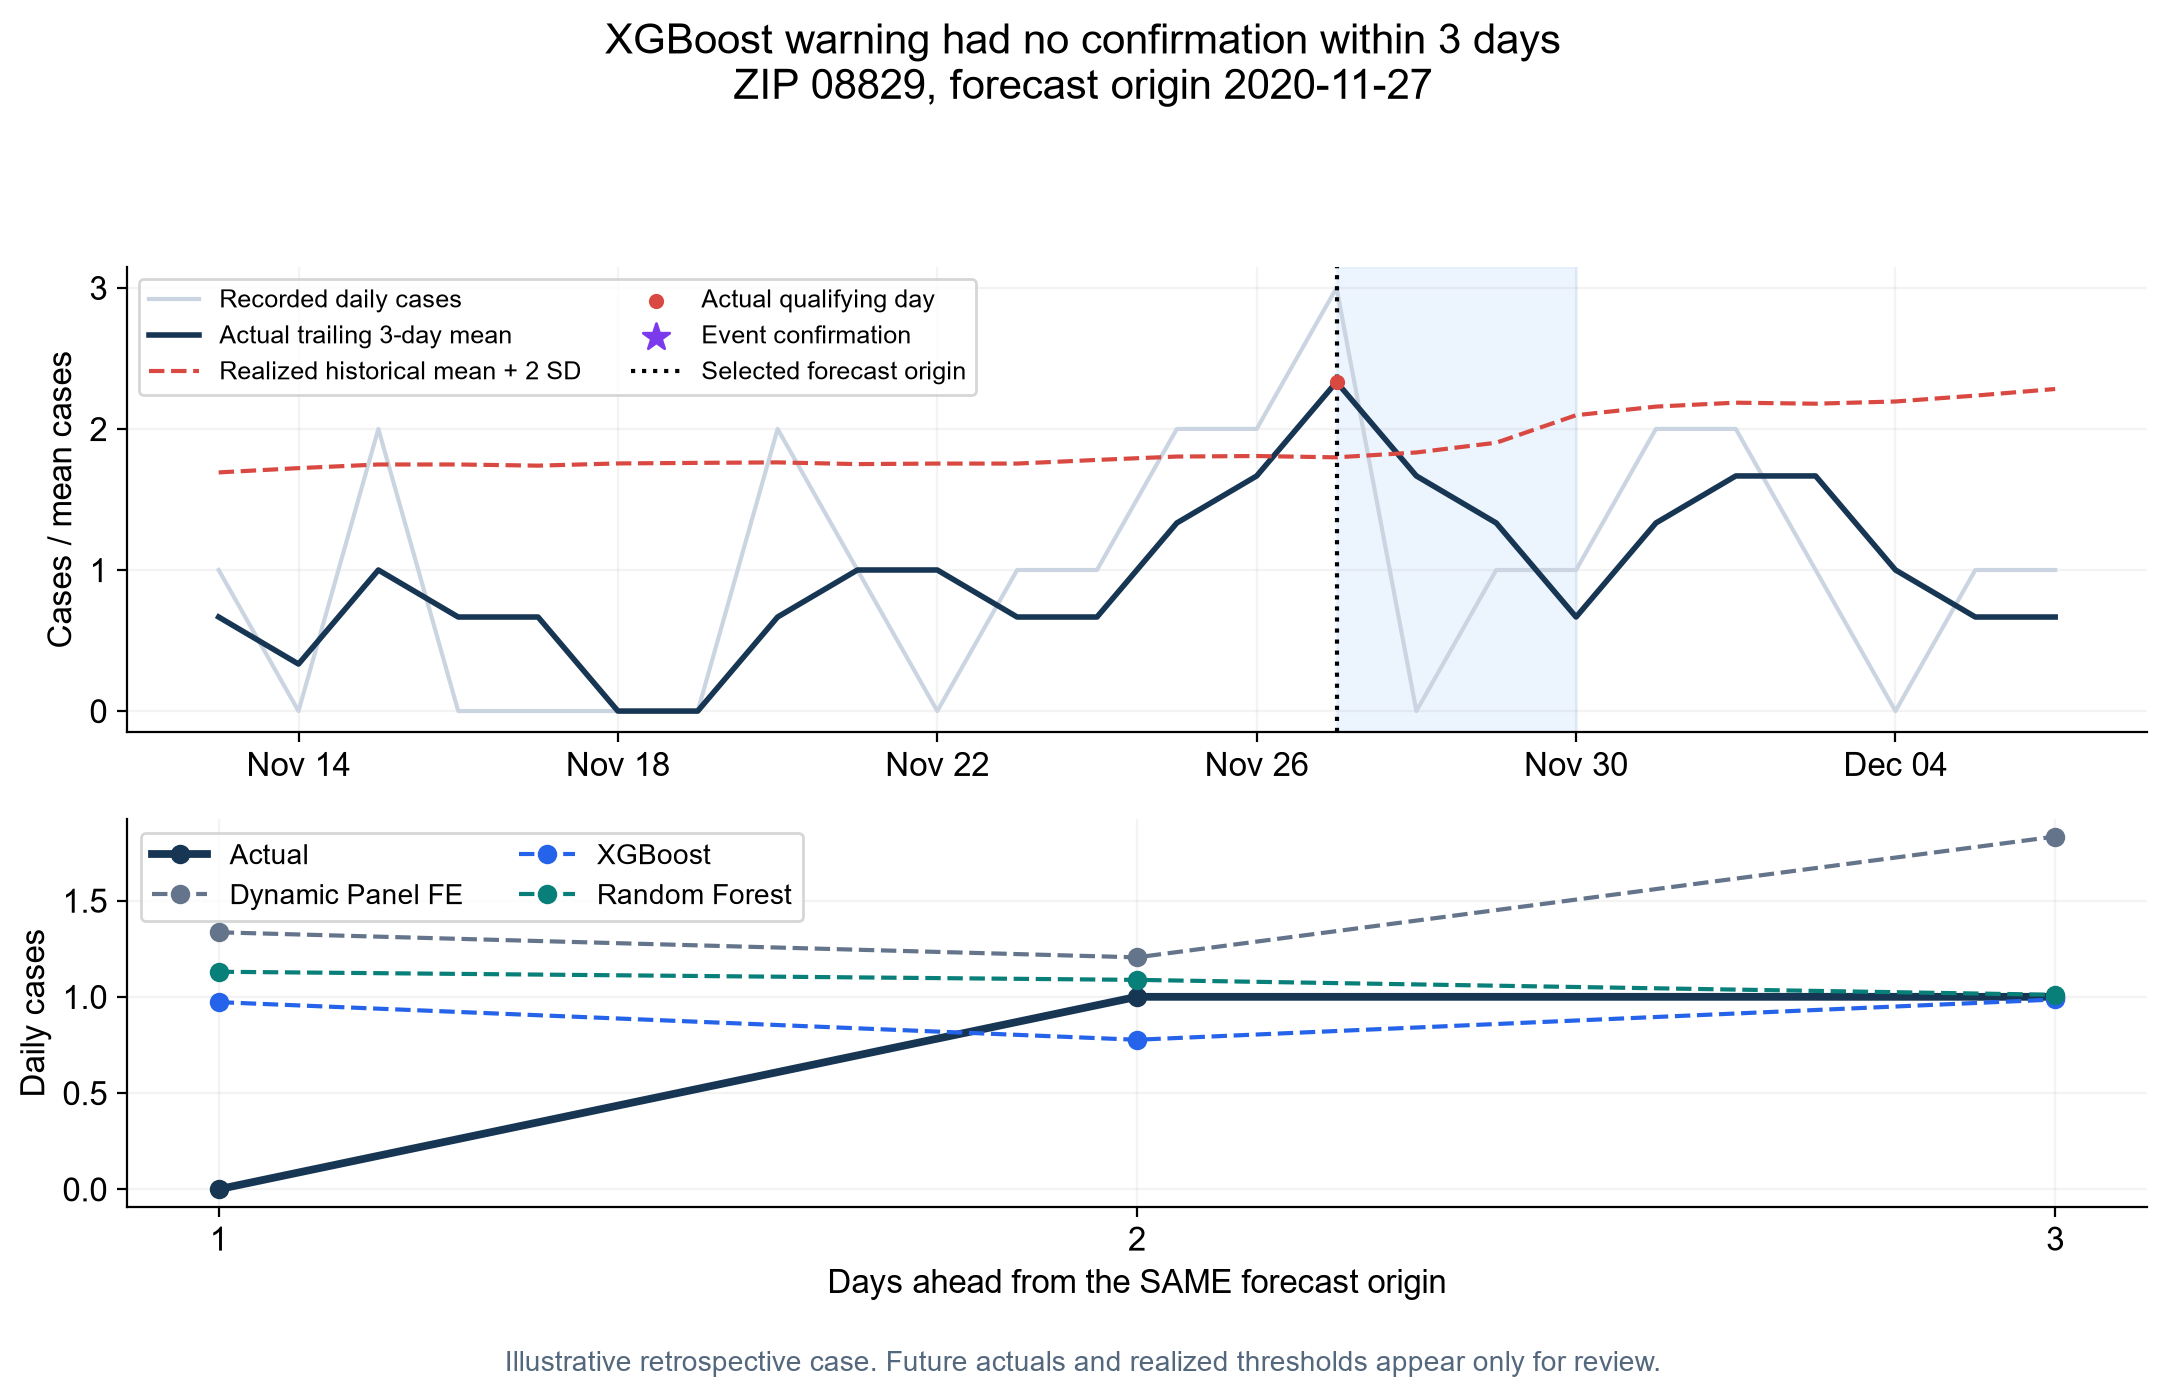

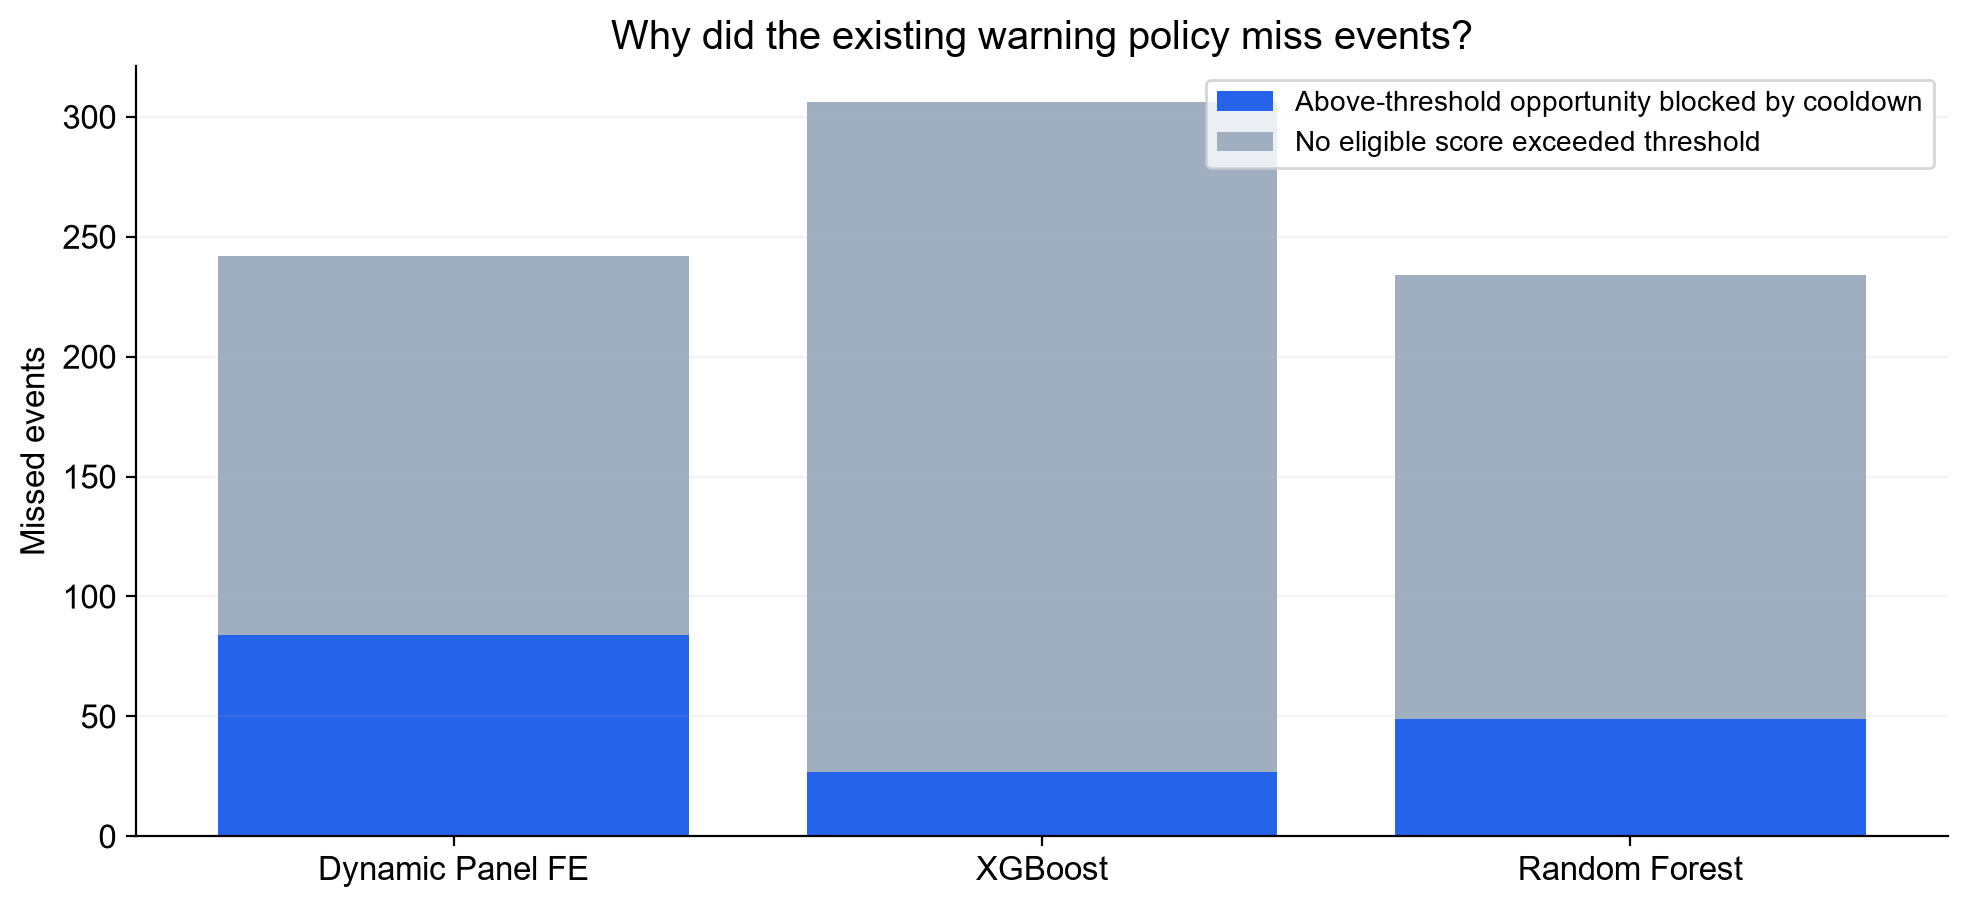

In [4]:
import pandas as pd
from IPython.display import display,Image
display(pd.read_csv(OUTPUT/"selected_cases.csv",dtype={"zip":"string"}))
display(pd.read_csv(OUTPUT/"case_model_diagnostics.csv",dtype={"zip":"string"}))
display(pd.read_csv(OUTPUT/"missed_reason_summary.csv"))
for name in ["01_shared_success.png","02_xgb_miss_other_detect.png","03_xgb_false_warning.png","04_missed_event_reasons.png"]:
    display(Image(filename=str(OUTPUT/"figures"/name)))